# Individual Behavior Time Budgets for African wild dogs

This notebook reproduces `figures/individual_time_budgets_camera_trap.png` from
the `etho-tools` individual-behavior
case study, **step by step**, and shows the prep that turns the published
per-frame annotations into `data/behavior_individual_matrix.csv`.

It is written to be reused on **your own data**: paths are relative to the
notebook, individual identities are assumed already anonymized, and the
behaviour/individual orderings are derived from the data rather than hard-coded.

### Data flow

```
frame_annotations.csv                  one row per annotated, visible frame
        │
        │  Part 1 — pivot behaviour x individual
        ▼
data/behavior_individual_matrix.csv    counts: behaviours (rows) x individuals (cols)
        │
        │  Part 2 — keep ethogram classes, row-normalise to %
        ▼
figures/individual_time_budgets_camera_trap.png
```

**Note:** `behavior_individual_matrix.csv` is an **all-sources** table — it has no camera
dimension. A *camera-trap* figure is the camera-trap **subset** of the
annotations, so it cannot be produced from the all-sources matrix alone.

**Components of this notebook:**

1. **Part 1** builds the all-sources `behavior_individual_matrix.csv` from
   `frame_annotations.csv` (the prep step).
2. **Part 2** builds a *camera-trap-filtered* table in the **same matrix shape**
   and feeds it to one plotting function. That same function, given the
   all-sources matrix, reproduces `individual_time_budgets.png`; given the
   camera-trap matrix, it reproduces `individual_time_budgets_camera_trap.png`.


## Setup

Run with any Python environment that has `pandas`, `numpy`, `matplotlib`, and
`seaborn`:

```bash
pip install pandas numpy matplotlib seaborn
```

Paths are relative to this notebook's folder
(`docs/case_studies/4_individual_behavior/`), so launch Jupyter from there (or
adjust `DATA_DIR` / `FIG_DIR` below).

### Data

The per-frame annotations come from the **WildDog-MV** dataset on Hugging Face:

> **imageomics/african_wild_dogs** — <https://huggingface.co/datasets/imageomics/african_wild_dogs>

The file you need is `annotations/frame_annotations.csv`. The next section can
download it automatically with `huggingface_hub`, or you can grab it from the
dataset's *Files* tab and drop it in `data/`. To reuse this notebook on your own
study, export per-frame annotations with the same columns (see Part 1) instead.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="darkgrid")

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Per-frame annotation table. Download it from the dataset release and place it
# in data/, or point this at your own annotations exported in the same schema
# (see the column table in Part 1).
FRAME_ANNOTATIONS = DATA_DIR / "frame_annotations.csv"

MATRIX_CSV = DATA_DIR / "behavior_individual_matrix.csv"

## Part 1 — Prep
 `frame_annotations.csv` → `behavior_individual_matrix.csv`

### 1.1 Load the per-frame annotations

`frame_annotations.csv` is the tidy, one-row-per-frame export of the
behavior/identity annotations. Each row is a single visible frame of a single
tracked animal. The columns this notebook uses:

| column | meaning |
|---|---|
| `behavior` | raw ethogram label, **including** visibility labels (`Out_of_view`, `Occluded`) |
| `behavior_class` | real behaviour only — visibility labels are blank/NaN here |
| `individual_id` | anonymized animal id (e.g. `1`–`9`) |
| `camera_type` | e.g. `camera_trap` or `drone` |
| `camera_source` | specific device, e.g. `GoPro_Hero7`, `DJI_drone` |

> Identities are assumed **already anonymized** — `individual_id` is used as-is.


In [7]:
frames = pd.read_csv(FRAME_ANNOTATIONS)
frames["individual_id"] = frames["individual_id"].astype(str)
print(f"{len(frames):,} frame rows")
frames.head()

161,398 frame rows


,video_name,task_id,track_id,frame,behavior,behavior_class,individual_id,visibility,bbox_x1,bbox_y1,bbox_x2,bbox_y2,camera_source,camera_type
0,DJI0035_0,8682,49,27002,Locomotion,Locomotion,6,visible,48.5,140.8,48.5,140.8,DJI_drone,drone
1,DJI0035_0,8682,49,27003,Locomotion,Locomotion,6,visible,48.5,140.8,48.5,140.8,DJI_drone,drone
2,DJI0035_0,8682,49,27004,Locomotion,Locomotion,6,visible,48.5,140.8,48.5,140.8,DJI_drone,drone
3,DJI0035_0,8682,49,27005,Locomotion,Locomotion,6,visible,48.5,140.8,48.5,140.8,DJI_drone,drone
4,DJI0035_0,8682,49,27006,Locomotion,Locomotion,6,visible,48.5,140.8,48.5,140.8,DJI_drone,drone


In [8]:
# Quick look at the values we rely on
print("camera_type  :", sorted(frames["camera_type"].unique()))
print("individual_id:", sorted(frames["individual_id"].unique()))
print("behavior     :", sorted(frames["behavior"].dropna().unique()))

camera_type  : ['camera_trap', 'drone']
individual_id: ['0', '1', '2', '3', '4', '5', '6', '7', '8']
behavior     : ['Feeding', 'Inspect_environment', 'Locomotion', 'Occluded', 'Other', 'Other_maintainence', 'Out_of_view', 'Positive_social_interactions', 'Resting', 'Stereotypic']


### 1.2 A couple of small helpers

We sort individuals numerically when they look like numbers (so `10` comes after
`9`, not after `1`), and we order behavior rows by overall frequency — both are
derived from the data, not hard-coded.


In [9]:
def sort_individuals(ids):
    """Sort individual ids numerically when possible, else lexicographically."""
    ids = list(ids)
    try:
        return sorted(ids, key=lambda x: int(x))
    except (TypeError, ValueError):
        return sorted(ids, key=str)


def frequency_order(matrix):
    """Row labels ordered by total count, descending."""
    return matrix.sum(axis=1).sort_values(ascending=False).index.tolist()

### 1.3 Pivot to the behavior × individual matrix

The matrix uses the **raw `behavior` column** (not `behavior_class`) so the
visibility labels `Out_of_view` / `Occluded` are kept as rows. Rows are ordered
by overall frequency; columns are the (already anonymized) individuals.


In [10]:
individuals = sort_individuals(frames["individual_id"].unique())

matrix = (
    frames.groupby(["behavior", "individual_id"]).size()
          .unstack(fill_value=0)
          .reindex(columns=individuals, fill_value=0)
)
matrix = matrix.reindex(frequency_order(matrix))
matrix.index.name = "behavior"
matrix

individual_id,0,1,2,3,4,5,6,7,8
behavior,,,,,,,,,
Locomotion,704,5669,8009,6966,6951,4221,11602,7303,9820
Resting,40,8406,4066,3356,3569,1605,7009,2324,5156
Inspect_environment,21,4067,2004,3081,2572,1873,3528,4301,5281
Out_of_view,24356,0,0,1,472,1,263,37,598
Feeding,0,467,0,4023,21,0,0,0,0
Occluded,1877,0,237,108,87,854,194,37,511
Positive_social_interactions,0,84,535,655,869,92,168,567,107
Stereotypic,0,0,0,0,0,0,357,0,0
Other_maintainence,0,0,0,0,0,0,0,0,248


### 1.4 Write `behavior_individual_matrix.csv`

In [11]:
matrix.to_csv(MATRIX_CSV)
print(f"Wrote {MATRIX_CSV}")

# Round-trip check
reloaded = pd.read_csv(MATRIX_CSV).set_index("behavior")
reloaded.columns = [str(c) for c in reloaded.columns]
assert (reloaded.values == matrix.values).all()
print("Round-trip OK.")

Wrote data/behavior_individual_matrix.csv
Round-trip OK.


# Part 2 
 `behavior_individual_matrix.csv` → camera-trap figure

### 2.1 Plotting configuration (the published ethogram of 6 classes)

The figure collapses the raw labels to the **real ethogram classes** and drops
the two visibility labels (`Out_of_view`, `Occluded`) — they describe camera
visibility, not behaviour. Edit `BEHAVIOR_ORDER` / `DISPLAY_NAMES` to match your
own ethogram.

> To reproduce the committed PNG exactly we keep a single `Other` column and let
> `reindex` drop the small `Stereotypic` / `Other_maintainence` categories. To
> instead fold them into `Other`, see the commented lines in `matrix_to_props`.


In [12]:
BEHAVIOR_ORDER = [
    "Locomotion", "Resting", "Inspect_environment",
    "Feeding", "Positive_social_interactions", "Other",
]
DISPLAY_NAMES = {
    "Locomotion": "Locomotion",
    "Resting": "Resting",
    "Inspect_environment": "Inspect\nenvironment",
    "Feeding": "Feeding",
    "Positive_social_interactions": "Social\ninteractions",
    "Other": "Other",
}
BEHAVIOR_PALETTE = dict(zip(
    BEHAVIOR_ORDER, sns.color_palette("tab20", len(BEHAVIOR_ORDER))
))

### 2.2 Helpers: matrix → row-normalised %, and the stacked bar plot

`matrix_to_props` takes **any** behaviour-matrix-shaped table (rows =
behaviours, columns = individuals) and returns individuals × behaviour
percentages. `plot_time_budgets` draws the stacked horizontal bars.


In [13]:
def matrix_to_props(behaviour_matrix):
    """behaviours x individuals counts -> individuals x BEHAVIOR_ORDER, row %."""
    counts = behaviour_matrix.copy()
    counts.columns = [str(c) for c in counts.columns]
    counts = counts.T  # -> individuals x behaviours

    # To FOLD Stereotypic/Other_maintainence into Other instead of dropping:
    # for col in ("Stereotypic", "Other_maintainence"):
    #     if col in counts.columns:
    #         counts["Other"] = counts.get("Other", 0) + counts[col]

    counts = counts.reindex(columns=BEHAVIOR_ORDER, fill_value=0)
    counts = counts.reindex(sort_individuals(counts.index))
    totals = counts.sum(axis=1).replace(0, 1)
    return counts.div(totals, axis=0) * 100


def plot_time_budgets(props, title, out_path):
    individuals = list(props.index)
    fig, ax = plt.subplots(figsize=(10, 5))
    left = np.zeros(len(individuals))
    for behavior in BEHAVIOR_ORDER:
        vals = props[behavior].values
        ax.barh(
            individuals, vals, left=left,
            color=BEHAVIOR_PALETTE[behavior],
            label=DISPLAY_NAMES[behavior].replace("\n", " "),
            edgecolor="white", linewidth=0.5,
        )
        left += vals

    ax.set_xlabel("Time Budget (%)", fontsize=13)
    ax.set_ylabel("Individual", fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.legend(loc="lower right", fontsize=9, ncol=2,
              title="Behavior", title_fontsize=10)
    ax.set_xlim(0, 100)
    ax.invert_yaxis()  # first individual at the top

    plt.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    fig.savefig(out_path.with_suffix(".pdf"), dpi=300, bbox_inches="tight")
    print(f"Saved: {out_path}")
    return fig

### 2.3 Build the **camera-trap** matrix

This is the step that needs more than the all-sources CSV: filter
`frame_annotations.csv` to `camera_type == "camera_trap"` first, then pivot to
the same matrix shape. Here we use `behavior_class` (real behaviors only),
which is what the figure shows.


In [14]:
camera_trap = frames[frames["camera_type"] == "camera_trap"]
print(f"{len(camera_trap):,} camera-trap frames "
      f"from sources: {sorted(camera_trap['camera_source'].unique())}")

real = camera_trap[camera_trap["behavior_class"].notna()
                   & (camera_trap["behavior_class"] != "")]
camera_trap_matrix = (
    real.groupby(["behavior_class", "individual_id"]).size()
        .unstack(fill_value=0)
        .reindex(columns=individuals, fill_value=0)
)
camera_trap_matrix.index.name = "behavior"
camera_trap_matrix

110,154 camera-trap frames from sources: ['GoPro_Hero11', 'GoPro_Hero7']


individual_id,0,1,2,3,4,5,6,7,8
behavior,,,,,,,,,
Feeding,0,0,0,4023,0,0,0,0,0
Inspect_environment,0,712,110,1088,513,0,30,0,653
Locomotion,397,4480,4330,4535,4188,2972,6742,3715,8245
Other,0,0,37,0,0,0,0,0,31
Other_maintainence,0,0,0,0,0,0,0,0,248
Positive_social_interactions,0,34,442,444,645,71,121,465,107
Resting,0,8341,3918,2090,3131,1493,6697,1995,4404
Stereotypic,0,0,0,0,0,0,357,0,0


### 2.4 Normalise to percentages and plot the camera-trap figure

behavior  Locomotion  Resting  Inspect_environment  Feeding  Positive_social_interactions  Other
0              100.0      0.0                  0.0      0.0                           0.0    0.0
1               33.0     61.5                  5.2      0.0                           0.3    0.0
2               49.0     44.3                  1.2      0.0                           5.0    0.4
3               37.2     17.2                  8.9     33.0                           3.6    0.0
4               49.4     36.9                  6.1      0.0                           7.6    0.0
5               65.5     32.9                  0.0      0.0                           1.6    0.0
6               49.6     49.3                  0.2      0.0                           0.9    0.0
7               60.2     32.3                  0.0      0.0                           7.5    0.0
8               61.3     32.8                  4.9      0.0                           0.8    0.2
Saved: figures/individual_time

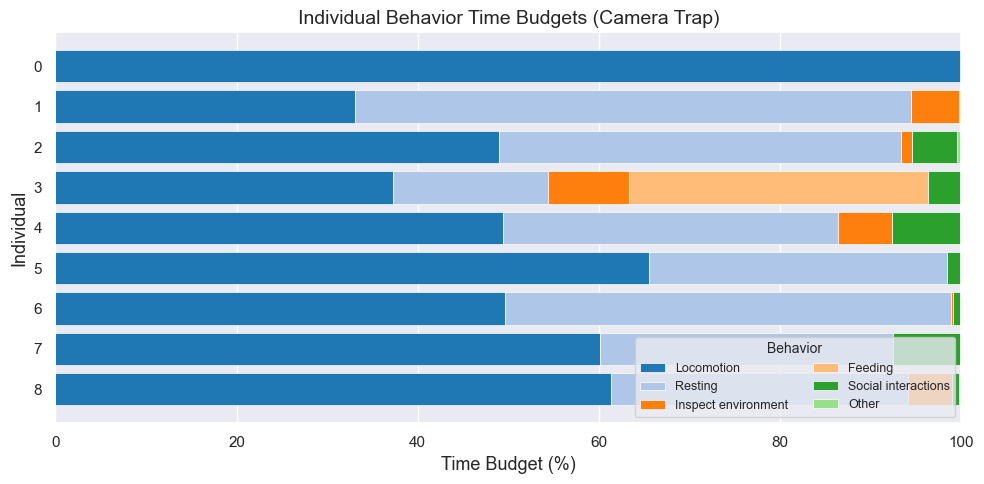

In [15]:
ct_props = matrix_to_props(camera_trap_matrix)
print(ct_props.round(1).to_string())

plot_time_budgets(
    ct_props,
    title="Individual Behavior Time Budgets (Camera Trap)",
    out_path=FIG_DIR / "individual_time_budgets_camera_trap.png",
)
plt.show()

### 2.5 (Bonus) All-sources figure straight from the matrix CSV

To show the same plotting path works directly on `behavior_individual_matrix.csv`,
here is the all-sources figure (`individual_time_budgets.png`) — it loads the
CSV and reuses `matrix_to_props` / `plot_time_budgets` unchanged.


Saved: figures/individual_time_budgets.png


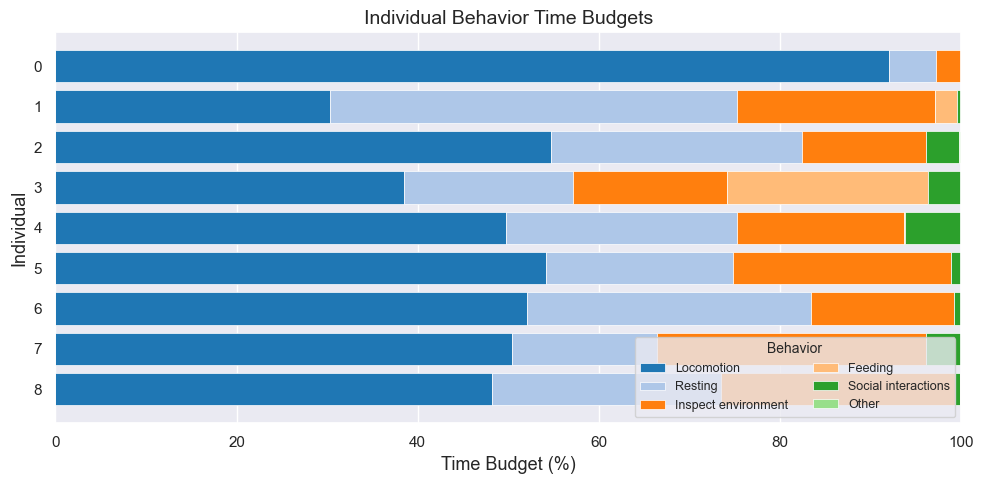

In [16]:
all_matrix = pd.read_csv(MATRIX_CSV).set_index("behavior")

plot_time_budgets(
    matrix_to_props(all_matrix),
    title="Individual Behavior Time Budgets",
    out_path=FIG_DIR / "individual_time_budgets.png",
)
plt.show()

## Recap

- **Part 1** built `data/behavior_individual_matrix.csv` from
  `frame_annotations.csv` by pivoting `behavior` × `individual_id`.
- **Part 2** produced `figures/individual_time_budgets_camera_trap.png` from a
  camera-trap-filtered matrix, and the *same* plotting function reproduced the
  all-sources `individual_time_budgets.png` from the CSV.

To adapt this to your own data: export per-frame annotations with the columns in
Part 1, drop the file at `FRAME_ANNOTATIONS`, and edit `BEHAVIOR_ORDER` /
`DISPLAY_NAMES` to match your ethogram.
